In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import multi.modules.dplot as dplot
from statannotations.Annotator import Annotator

In [2]:
acc_wsub = np.load("multi/acc/comb/acc_ori.npy", allow_pickle=True).item()["xDAWN+LR"]
acc_csub = np.load("multi/acc/comb/acc_csub.npy", allow_pickle=True).item()["xDAWN+LR"]
acc = {"Within-subject":acc_wsub,"Cross-subject":acc_csub}
# colors
blues = np.array(sns.color_palette("Blues"))
oranges = np.array(sns.color_palette("Oranges"))

In [3]:
records_binary,records_four = [], []
for m in acc:
    for s in range(len(acc[m])):
        records_binary.append({
            "Type": m,
            "Decision": "Single Window",
            "Accuracy": acc[m][s,0,0]})
        records_binary.append({
            "Type": m,
            "Decision": "With TI",
            "Accuracy": acc[m][s,0,1]})
        records_four.append({
            "Type": m,
            "Decision": "Single Window",
            "Accuracy": acc[m][s,1,0]})
        records_four.append({
            "Type": m,
            "Decision": "With TI",
            "Accuracy": acc[m][s,1,1]})
df_b = pd.DataFrame(records_binary)
df_f = pd.DataFrame(records_four)

/tmp/ipykernel_646942/3056089286.py:10: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=df_b,x="Type",y="Accuracy",hue="Decision",


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Cross-subject_Single Window vs. Cross-subject_With TI: t-test paired samples, P_val:7.846e-06 t=-6.064e+00
Within-subject_Single Window vs. Within-subject_With TI: t-test paired samples, P_val:2.458e-04 t=-4.499e+00


/tmp/ipykernel_646942/3056089286.py:23: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=df_f,x="Type",y="Accuracy",hue="Decision",


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Cross-subject_Single Window vs. Cross-subject_With TI: t-test paired samples with Benjamini-Hochberg correction, P_val:3.525e-03 t=-3.329e+00
Within-subject_Single Window vs. Within-subject_With TI: t-test paired samples with Benjamini-Hochberg correction, P_val:1.308e-03 t=-3.766e+00


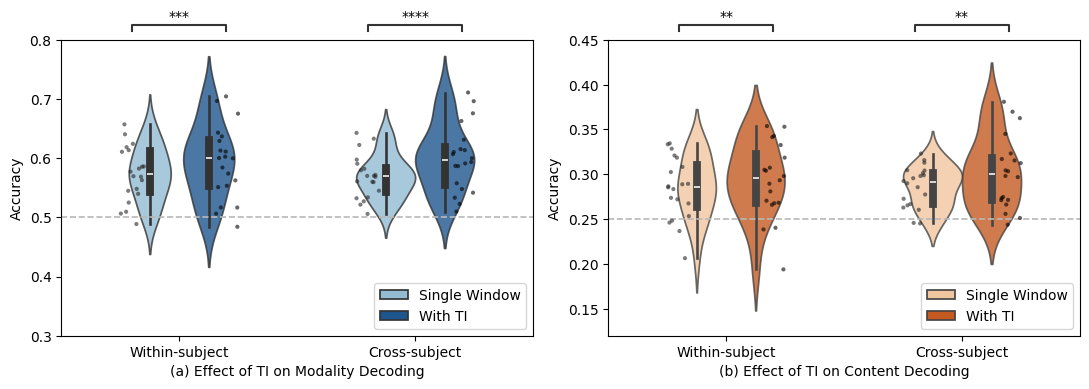

In [4]:
# TI comparisons
pairs_ti = [
    (("Within-subject", "Single Window"),("Within-subject", "With TI")),
    (("Cross-subject", "Single Window"), ("Cross-subject", "With TI")),
]
fig = plt.figure(figsize = (11,4))
# ---------- Binary ----------
ax = plt.subplot2grid((1, 2), (0, 0))
dplot.plot_violin(df_b, ax, x="Type", hue="Decision", palette=list(blues[[2,5]]), alpha=0.8)
sns.stripplot(data=df_b,x="Type",y="Accuracy",hue="Decision",
    dodge=True,color="black",alpha=0.6,size=3,ax=ax,legend=False)
ax.set_xlabel("(a) Effect of TI on Modality Decoding")
ax.axhline(0.5, color="#B8B8B8", linestyle='--', linewidth=1.2)
ax.legend(loc="lower right")
ax.set_ylim(0.3,0.8)

annotator = Annotator(ax,pairs_ti,data=df_b,x="Type",y="Accuracy", hue="Decision")
annotator.configure(test="t-test_paired",text_format="star",loc="outside")
annotator.apply_and_annotate()
# ---------- Four ----------
ax = plt.subplot2grid((1, 2), (0, 1))
dplot.plot_violin(df_f, ax, x="Type", hue="Decision", palette=list(oranges[[1,4]]), alpha=0.8)
sns.stripplot(data=df_f,x="Type",y="Accuracy",hue="Decision",
    dodge=True,color="black",alpha=0.6,size=3,ax=ax,legend=False)
ax.set_xlabel("(b) Effect of TI on Content Decoding")
ax.axhline(0.25, color="#B8B8B8", linestyle='--', linewidth=1.2)
ax.legend(loc="lower right")
ax.set_ylim(0.12,0.45)

annotator = Annotator(ax,pairs_ti,data=df_f,x="Type",y="Accuracy", hue="Decision")
annotator.configure(test="t-test_paired",text_format="star",comparisons_correction="fdr_bh",loc="outside")
annotator.apply_and_annotate()
plt.tight_layout()
plt.savefig("multi/fig/ti.pdf", bbox_inches="tight")
plt.show()